<a href="https://colab.research.google.com/github/chulsoo3060/YOLO_SEJONG/blob/main/YOLO_BN_Statistics_Adaptation_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
!pip -q install ultralytics pyyaml

import cv2
import copy
import random
import shutil
import zipfile
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from pathlib import Path
from google.colab import files
from ultralytics import YOLO
from ultralytics.data.augment import LetterBox
from IPython.display import display

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
ROOT = Path("/content/bn_adaptation_exp")
ROOT.mkdir(exist_ok=True)

PyTorch: 2.14.1+cu130
GPU: True Tesla T4


In [6]:
uploaded = files.upload()
pt_files = [k for k in uploaded if k.lower().endswith(".pt")]
zip_files = [k for k in uploaded if k.lower().endswith(".zip")]
assert len(pt_files) == 1, f"모델 .pt 파일 1개가 필요합니다: {pt_files}"
assert len(zip_files) == 1, f"데이터셋 ZIP 1개가 필요합니다: {zip_files}"
WEIGHTS = str(Path("/content") / pt_files[0])
ZIP_FILE = Path("/content") / zip_files[0]
print("모델:", WEIGHTS)
print("데이터셋:", ZIP_FILE)

Saving best_mine.pt to best_mine (1).pt
Saving Yolo.v1i.yolov11.zip to Yolo.v1i.yolov11 (1).zip
모델: /content/best_mine (1).pt
데이터셋: /content/Yolo.v1i.yolov11 (1).zip


In [7]:
DATA_ROOT = ROOT / "sanghyeon"
DATA_ROOT.mkdir(exist_ok=True)
with zipfile.ZipFile(ZIP_FILE) as z:
    z.extractall(DATA_ROOT)

yaml_path = DATA_ROOT / "data.yaml"
assert yaml_path.exists(), f"data.yaml 없음: {yaml_path}"
with open(yaml_path, encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

assert cfg.get("names") in (["my_bottle"], {0: "my_bottle"}), cfg.get("names")
cfg["path"] = str(DATA_ROOT)
cfg["train"] = "train/images"
cfg["val"] = "valid/images"
cfg["test"] = "test/images"
with open(yaml_path, "w", encoding="utf-8") as f:
    yaml.safe_dump(cfg, f, allow_unicode=True, sort_keys=False)

def images_in(split):
    folder = DATA_ROOT / split / "images"
    assert folder.is_dir(), folder
    return sorted(p for p in folder.iterdir() if p.suffix.lower() in (".jpg", ".jpeg", ".png"))

train_images = images_in("train")
val_images = images_in("valid")
test_images = images_in("test")
assert len(train_images) >= 100, "적응용 Train 이미지가 100장 미만"
print("Train:", len(train_images), "Validation:", len(val_images), "Test:", len(test_images))

# 같은 순서의 누적 부분집합을 사용해서 0/10/30/50/100장 비교
rng = random.Random(42)
rng.shuffle(train_images)
adapt_pool = train_images[:100]
print("적응에 사용할 100장 선택 완료. Validation 및 Test는 적응에 사용하지 않습니다.")

Train: 155 Validation: 31 Test: 15
적응에 사용할 100장 선택 완료. Validation 및 Test는 적응에 사용하지 않습니다.


In [8]:
BN_TYPES = nn.modules.batchnorm._BatchNorm

def get_bn_modules(net):
    return {n: m for n, m in net.named_modules()
            if isinstance(m, BN_TYPES) and m.track_running_stats
            and m.running_mean is not None and m.running_var is not None}

def get_bn_stats(net):
    return {
        name: {
            "mean": module.running_mean.detach().cpu().clone(),
            "var": module.running_var.detach().cpu().clone()
        }
        for name, module in get_bn_modules(net).items()
    }

def load_bn_stats(net, stats):
    modules = get_bn_modules(net)
    for name, vals in stats.items():
        with torch.no_grad():
            modules[name].running_mean.copy_(vals["mean"].to(modules[name].running_mean.device))
            modules[name].running_var.copy_(vals["var"].to(modules[name].running_var.device))

def image_tensor(p, letterbox):
    im = cv2.imread(str(p))
    if im is None:
        raise ValueError(f"이미지를 읽지 못했습니다: {p}")
    im = letterbox(image=im)
    im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
    # RGB [0, 1] / NCHW / float32
    return torch.from_numpy(np.ascontiguousarray(im.transpose(2, 0, 1))).float().div_(255)

def adapt_bn(num_images, batch_size=8):
    y = YOLO(WEIGHTS)
    net = y.model.to(DEVICE)
    net.eval()
    for p in net.parameters():
        p.requires_grad_(False)

    initial = get_bn_stats(net)
    before_weights = {k: p.detach().cpu().clone() for k, p in net.named_parameters()}

    # BN만 train 모드 (파라미터는 고정된 채 running statistics만 갱신)
    bn_modules = get_bn_modules(net)
    assert bn_modules, "BN 계층을 찾지 못했습니다."
    for m in bn_modules.values():
        m.train()

    box = LetterBox(new_shape=(640, 640), auto=False, scale_fill=False, scaleup=True, stride=32)
    chosen = adapt_pool[:num_images]

    with torch.no_grad():
        for start in range(0, len(chosen), batch_size):
            batch_paths = chosen[start:start + batch_size]
            x = torch.stack([image_tensor(p, box) for p in batch_paths]).to(DEVICE)
            _ = net(x)

    after = get_bn_stats(net)
    max_param_diff = max(
        (p.detach().cpu() - before_weights[k]).abs().max().item()
        for k, p in net.named_parameters()
    )
    assert max_param_diff == 0.0, f"모델 파라미터가 변했습니다: {max_param_diff}"

    # 원본 체크포인트를 나중에 로드했을 때 BN 통계량만 덮어쓰도록 저장
    if num_images == 100:
        torch.save(after, ROOT / "adapted_bn_stats_100.pt")
    return initial, after, max_param_diff

def bn_diff_rows(before, after, n):
    rows = []
    for layer in before:
        a, b = before[layer], after[layer]
        dmean = (b["mean"] - a["mean"]).abs().mean().item()
        dvar = (b["var"] - a["var"]).abs().mean().item()
        rows.append({
            "images": n, "layer": layer,
            "mean_abs_change": dmean,
            "var_abs_change": dvar,
            "mean_relative_change": dmean / (a["mean"].abs().mean().item() + 1e-6),
            "var_relative_change": dvar / (a["var"].abs().mean().item() + 1e-6)
        })
    return rows

print("함수 준비 완료")

함수 준비 완료


In [9]:
STEPS = [0, 10, 30, 50, 100]
records, bn_rows = [], []
stats_by_step = {}

for n in STEPS:
    print(f"\n===== BN 적응 이미지: {n}장 =====")
    before, after, max_param_diff = adapt_bn(n)
    stats_by_step[n] = after
    bn_rows.extend(bn_diff_rows(before, after, n))

    # 평가용 모델은 매번 원본에서 새로 만들고 BN 통계량만 복사
    y_eval = YOLO(WEIGHTS)
    load_bn_stats(y_eval.model, after)
    m = y_eval.val(
        data=str(yaml_path), split="val", imgsz=640, batch=1,
        device=DEVICE, plots=False, verbose=False,
        project=str(ROOT / "valid_runs"), name=f"bn_{n}", exist_ok=True
    )
    records.append({
        "adapt_images": n,
        "Precision": float(m.box.mp),
        "Recall": float(m.box.mr),
        "mAP50": float(m.box.map50),
        "mAP50-95": float(m.box.map),
        "max_parameter_change": max_param_diff
    })
    print("mAP50-95 =", round(float(m.box.map), 4), "최대 파라미터 변화 =", max_param_diff)

valid_df = pd.DataFrame(records)
bn_df = pd.DataFrame(bn_rows)
display(valid_df.round(5))
valid_df.to_csv(ROOT / "bn_adaptation_validation.csv", index=False)
bn_df.to_csv(ROOT / "bn_layer_statistics_changes.csv", index=False)


===== BN 적응 이미지: 0장 =====
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 571.9±168.0 MB/s, size: 18.0 KB)
val: Scanning /content/bn_adaptation_exp/sanghyeon/valid/labels... 31 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 31/31 597.3it/s 0.1s
val: New cache created: /content/bn_adaptation_exp/sanghyeon/valid/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 40.9it/s 0.8s
                   all         31         31      0.652      0.355      0.419      0.182
Speed: 1.2ms preprocess, 12.0ms inference, 0.0ms loss, 1.2ms postprocess per image
mAP50-95 = 0.1818 최대 파라미터 변화 = 0.0

===== BN 적응 이미지: 10장 =====
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parame

,adapt_images,Precision,Recall,mAP50,mAP50-95,max_parameter_change
0,0,0.65183,0.35484,0.41852,0.18177,0.0
1,10,0.62339,0.35484,0.44423,0.18748,0.0
2,30,0.47595,0.48387,0.45184,0.20237,0.0
3,50,0.56562,0.51613,0.54248,0.21816,0.0
4,100,0.52132,0.58065,0.54590,0.24924,0.0


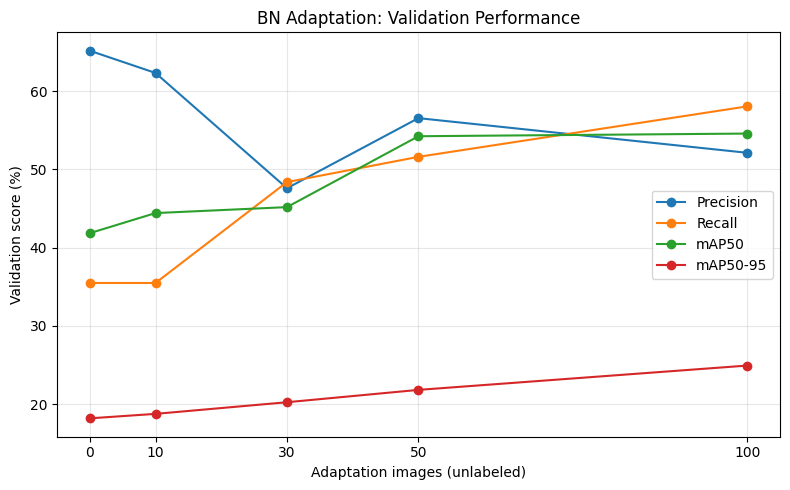

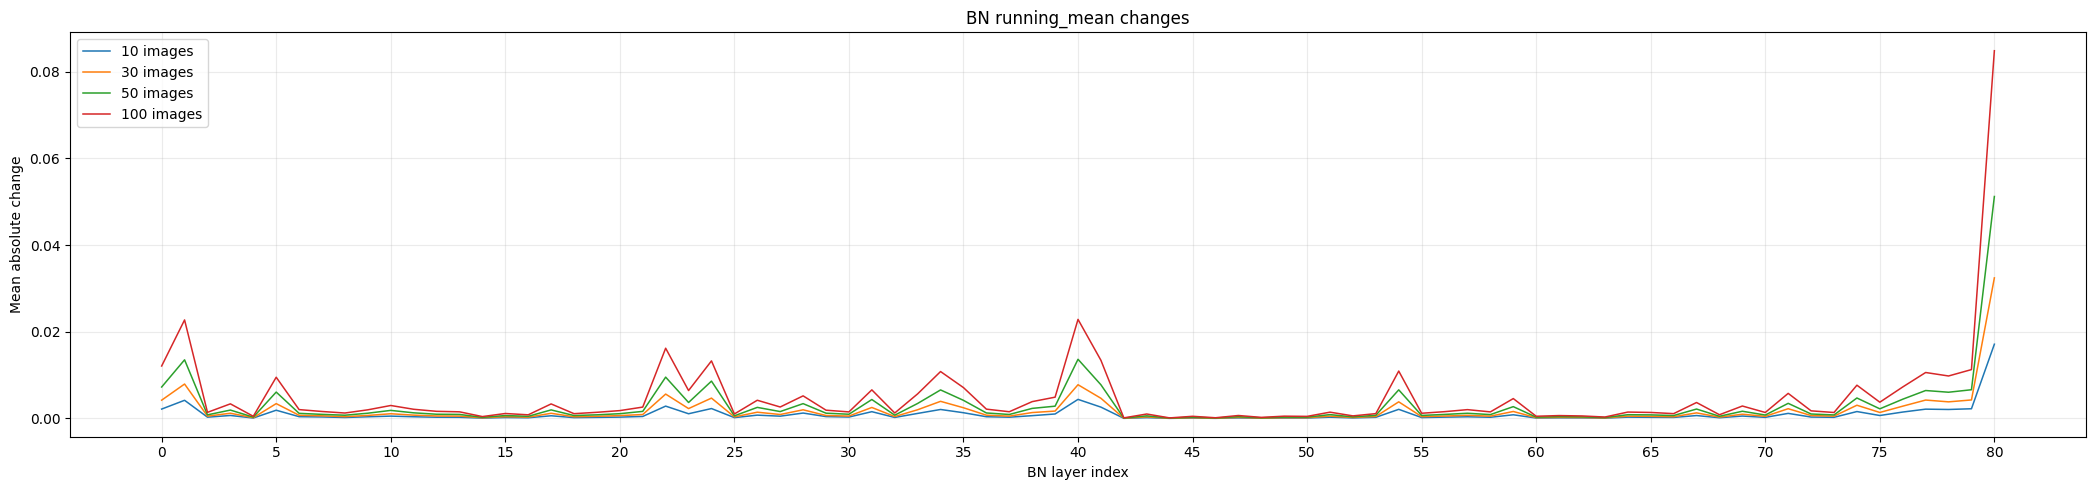

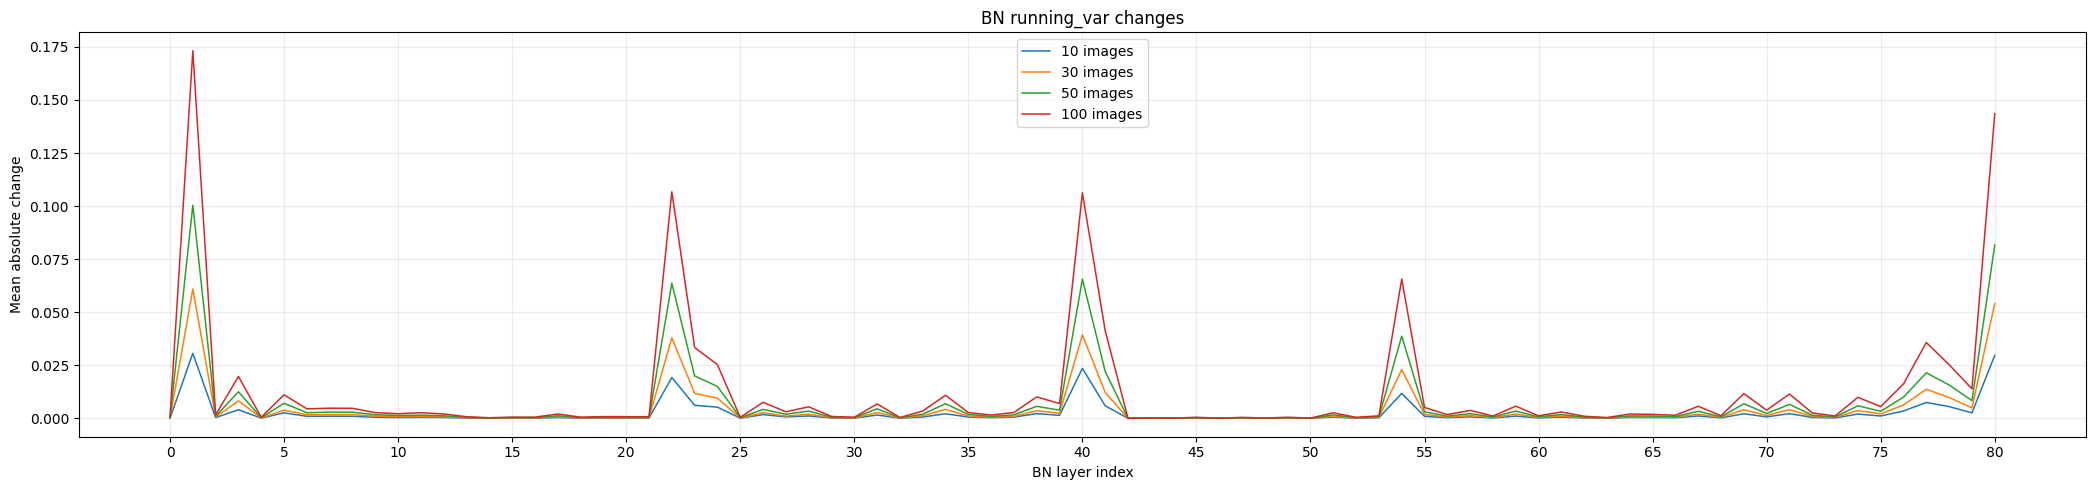

그래프 3개 생성 완료


In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
for col in ["Precision", "Recall", "mAP50", "mAP50-95"]:
    ax.plot(valid_df["adapt_images"], valid_df[col] * 100, marker="o", label=col)
ax.set(xlabel="Adaptation images (unlabeled)", ylabel="Validation score (%)",
       title="BN Adaptation: Validation Performance")
ax.set_xticks(STEPS)
ax.grid(alpha=.3)
ax.legend()
fig.tight_layout()
fig.savefig(ROOT / "bn_validation_performance.png", dpi=200)
plt.show()

for col, fname, title in [
    ("mean_abs_change", "bn_running_mean_changes.png", "BN running_mean changes"),
    ("var_abs_change", "bn_running_var_changes.png", "BN running_var changes")
]:
    tmp = bn_df.pivot(index="layer", columns="images", values=col)
    fig, ax = plt.subplots(figsize=(max(11, len(tmp) * .26), 5))
    x = np.arange(len(tmp))
    for n in [10, 30, 50, 100]:
        ax.plot(x, tmp[n].values, label=f"{n} images", linewidth=1.1)
    ax.set(xlabel="BN layer index", ylabel="Mean absolute change", title=title)
    ax.set_xticks(x[::max(1, len(x) // 14)])
    ax.set_xticklabels([str(i) for i in x[::max(1, len(x) // 14)]])
    ax.grid(alpha=.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(ROOT / fname, dpi=200)
    plt.show()

print("그래프 3개 생성 완료")

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 842.9±286.4 MB/s, size: 17.1 KB)
val: Scanning /content/bn_adaptation_exp/sanghyeon/test/labels... 15 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 15/15 1.9Kit/s 0.0s
val: New cache created: /content/bn_adaptation_exp/sanghyeon/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 37.3it/s 0.4s
                   all         15         15      0.718        0.2      0.188      0.108
Speed: 1.4ms preprocess, 14.5ms inference, 0.0ms loss, 1.2ms postprocess per image
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 743.7±299.6 M

,model,adapt_images,Precision,Recall,mAP50,mAP50-95
0,Original A,0,0.71791,0.2,0.18787,0.10788
1,BN-adapted A (100 images),100,0.80648,0.2,0.28922,0.14487


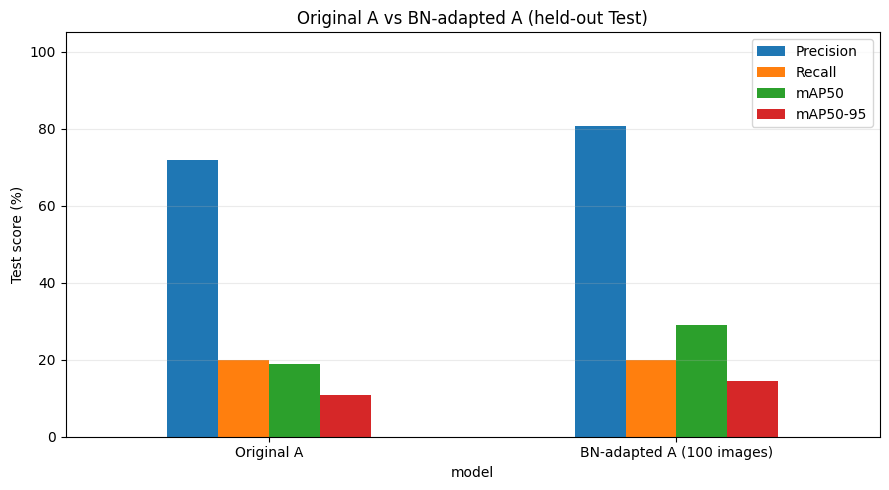

In [11]:
test_records = []
for n in [0, 100]:
    y_eval = YOLO(WEIGHTS)
    load_bn_stats(y_eval.model, stats_by_step[n])
    metrics = y_eval.val(
        data=str(yaml_path), split="test", imgsz=640, batch=1,
        device=DEVICE, plots=False, verbose=False,
        project=str(ROOT / "test_runs"), name=f"bn_{n}", exist_ok=True
    )
    test_records.append({
        "model": "Original A" if n == 0 else "BN-adapted A (100 images)",
        "adapt_images": n,
        "Precision": float(metrics.box.mp),
        "Recall": float(metrics.box.mr),
        "mAP50": float(metrics.box.map50),
        "mAP50-95": float(metrics.box.map)
    })
test_df = pd.DataFrame(test_records)
display(test_df.round(5))
test_df.to_csv(ROOT / "bn_adaptation_test.csv", index=False)
ax = test_df.set_index("model")[["Precision", "Recall", "mAP50", "mAP50-95"]].mul(100).plot.bar(
    figsize=(9, 5), rot=0)
ax.set(ylabel="Test score (%)", title="Original A vs BN-adapted A (held-out Test)")
ax.set_ylim(0, 105)
ax.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.savefig(ROOT / "bn_test_comparison.png", dpi=200)
plt.show()

In [12]:
zip_path = Path("/content/BN_Adaptation_Results.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zout:
    for name in [
        "bn_adaptation_validation.csv", "bn_adaptation_test.csv",
        "bn_layer_statistics_changes.csv",
        "bn_validation_performance.png",
        "bn_running_mean_changes.png",
        "bn_running_var_changes.png",
        "bn_test_comparison.png",
        "adapted_bn_stats_100.pt"
    ]:
        p = ROOT / name
        assert p.exists(), p
        zout.write(p, arcname=name)
print("다운로드 파일:", zip_path)
files.download(str(zip_path))

다운로드 파일: /content/BN_Adaptation_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>